# Example 31

Showcases the FMESH isotopic reaction rate.

The MCNP input calls for 

In [1]:
import openmc
import numpy as np
import copy

# Material definitions
materials=openmc.Materials()

# Natural Uranium
rho = 19.1
m100 = openmc.Material()
m100.add_nuclide('U238',0.992745) #,percent_type='ao')
m100.add_nuclide('U235',0.007200)
m100.set_density('g/cc',rho)

# M100x would technically be closer to natural uranium
m100x = openmc.Material()
m100x.add_element('U',1) 
m100x.set_density('g/cc',rho)

# Hypothetical Depleted Uranium
m200 = openmc.Material()
m200.add_nuclide('U238',0.9999)
m200.add_nuclide('U235',0.0001)
m200.set_density('g/cc',rho)

# Air
m300 = openmc.Material()
m300.add_nuclide('N14',0.755,percent_type='wo')
m300.add_nuclide('O16',0.231,percent_type='wo')
m300.add_element('Ar',0.013,percent_type='wo')

In [2]:
# Surface definition
s1 = openmc.Sphere(r=3,x0=4)
s2 = openmc.Sphere(r=3,x0=-4)
s3 = openmc.Sphere(r=10, boundary_type='vacuum')

# Cell definition
# When defining density via the cell, it will overwrite the density of the material.
# Also you can't set it in the constructor; you would have to create the obj then set the attr
c900 = openmc.Cell(fill=m100, region=-s1)
c901 = openmc.Cell(fill=m200, region=-s2)
c902 = openmc.Cell(fill=m300, region=+s1&+s2&-s3)
c903 = openmc.Cell(fill=None, region=+s3)
geometry=openmc.Geometry([c900,c901,c902,c903])

There are 3 fmesh cards:
fmesh04:n

fmesh14:n

fmesh24:n

The mesh tally calculates the track-length estimate of the particle flux averaged over a mesh cell in units of particles/cm^2. 

FMESH:n 
geom
origin -10 -10 -10
imesh 10
iints 100
jmesh 10
jints 100 
kmesh 10
kints 100

There are also three tally multipliers: 
+fm04
+fm14
+fm24

MCNP uses three meshes in order to get 

We will create an OpenMC mesh to do this. 

We can just add multiple scores to the mesh

In [3]:
# Mesh filter
mesh = openmc.RectilinearMesh(name='mesh-reaction-rate')
mesh.x_grid=np.linspace(-10,10,20)
mesh.y_grid=np.linspace(-10,10,20)
mesh.z_grid=np.linspace(-10,10,20)

# Equivalent to:
# meshx = openmc.RegularMesh()
# meshx.dimension = (10, 10, 10)
# meshx.lower_left = (-10, -10, -10)
# meshx.upper_right=(10,10,10)

In [4]:
# Tally creation using the mesh
mesh_filter = openmc.MeshFilter(mesh)

fx4 = openmc.Tally()
fx4.name = 'fission_rate'
fx4.nuclides = m100.get_nuclides()
fx4.scores = ['fission']
fx4.filters = [mesh_filter]

fx4x = openmc.Tally()
fx4x.nuclides = m100.get_nuclides()
fx4x.scores = ['fission']
fx4x.name='fine_rate'

mesh2 = openmc.RectilinearMesh(name='fine')
mesh2.x_grid=np.linspace(-10,10,50)
mesh2.y_grid=np.linspace(-10,10,50)
mesh2.z_grid=np.linspace(-10,10,50)
mesh2_filter = openmc.MeshFilter(mesh2)
fx4x.filters = [mesh2_filter]

tallies = openmc.Tallies(tallies=[fx4,fx4x])

In [5]:
settings = openmc.Settings()
settings.run_mode='fixed source'

# Source specification
source = openmc.IndependentSource()
source.space = openmc.stats.Point() # the cell is spherical
source.angle = openmc.stats.Isotropic() 
source.energy = openmc.stats.delta_function(2e6) # energy in eV 
settings.source = source

# 500,000 histories 
settings.particles = 1000
settings.batches = 500

In [6]:
model = openmc.model.Model(geometry, materials, settings, tallies)

In [7]:
w = 20
plots = openmc.Plots()

plot = openmc.SlicePlot()
plot.basis = 'xy'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
#plot.level=level
plots.append(plot)

plot = openmc.SlicePlot()
plot.basis = 'xz'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
#plot.level=level
plots.append(plot)

plot = openmc.SlicePlot()
plot.basis = 'yz'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
#plot.level = level
plots.append(plot)
openmc.plot_inline(plots)

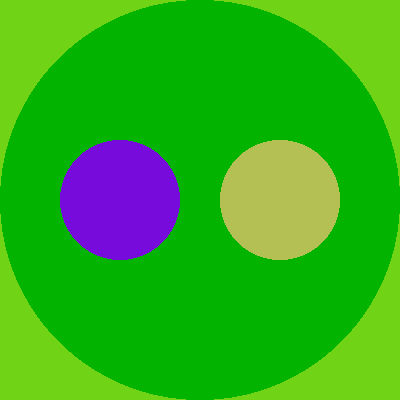

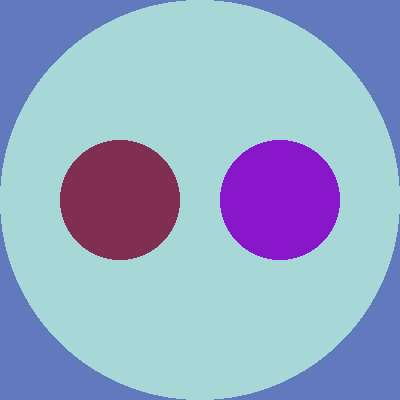

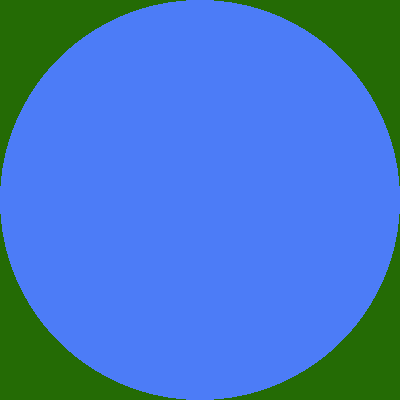

In [8]:
model.export_to_xml()

model.run() will return the resulting statepoint.h5 file that contains the results. 

In [9]:
sp_filename = model.run()

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

The 

In [ ]:
# open the results file
with openmc.StatePoint(sp_filename) as sp:
    results = sp.get_tally(name='fission_rate')
    df = results.get_pandas_dataframe()
    print(df[df['nuclide']=='U238']['mean'].sum())
    print(df[df['nuclide']=='U235']['mean'].sum())
    
    tally_stdev_sum = df['std. dev.'].sum()

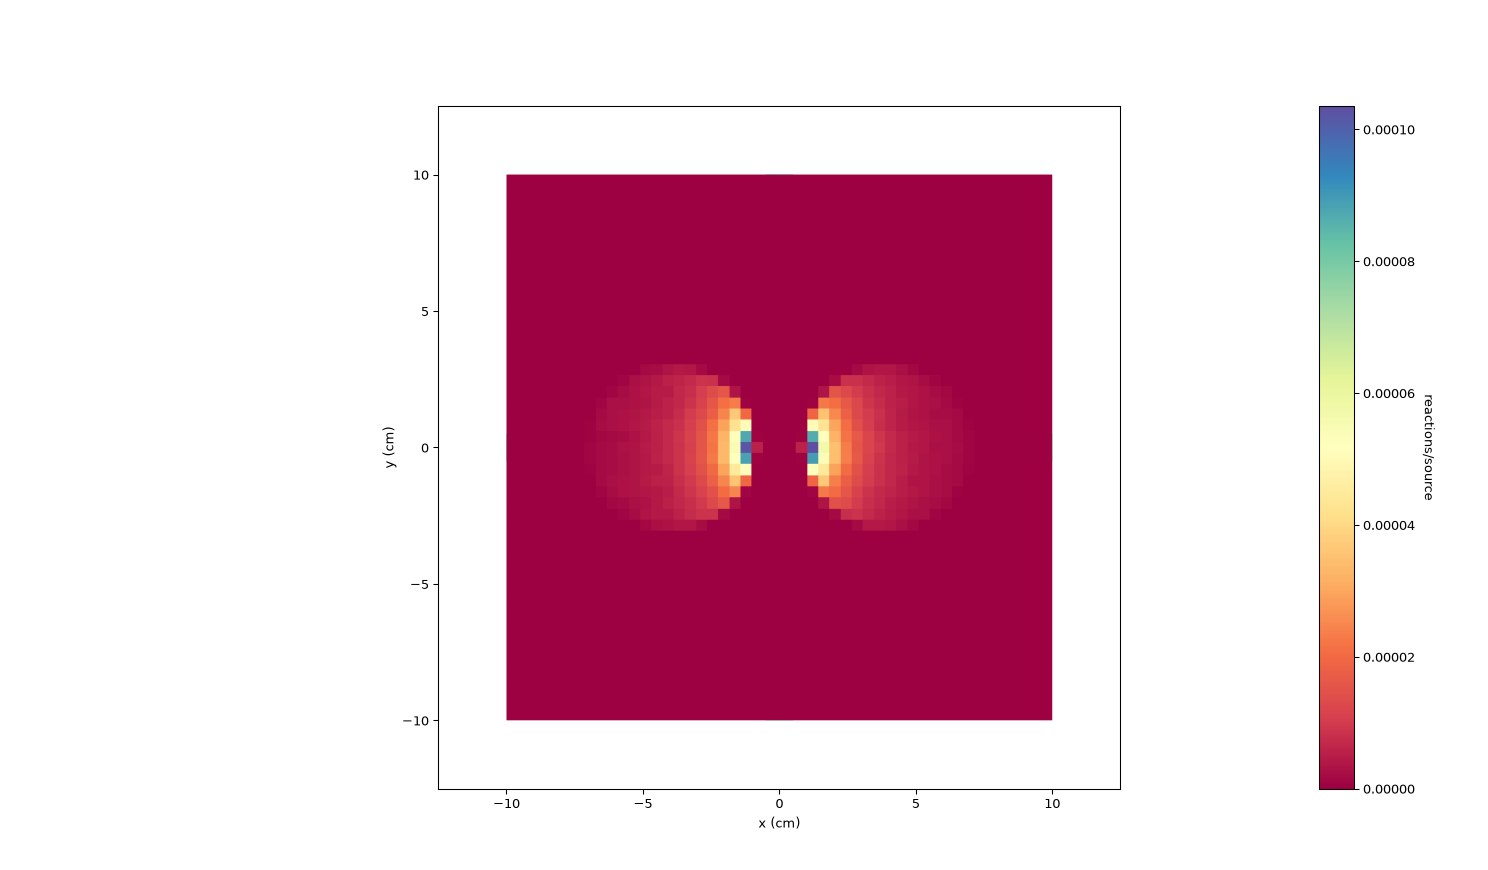